# Exploratory Data Analysis — Initial WA HyLogger Holes

## Purpose

This notebook explores the first real Western Australian NVCL boreholes used in the GSWA HyLogger Industry Adoption prototype.

The analysis investigates:

- dataset coverage and sampling structure;
- quality of the returned TSA mineral classifications;
- uTSAS mineral composition at sampled depths;
- Wt1 confidence behaviour;
- changes in mineral composition with depth;
- availability of mineral features required by the baseline classifier; and
- findings that require clarification or validation with GSWA before later modelling.

## Data scope

The current prototype retrieves `Grp1 uTSAS` mineral-group classifications and `Wt1 uTSAS` confidence values from NVCL.

For the current exploratory prototype, the NVCL scalar data is downsampled at a **20 m depth resolution**. This is an analysis setting and should not be interpreted as the native HyLogger scan resolution.

Raw mineral classifications retain `INVALID` and `NOTAROK` responses for quality analysis. These records are excluded when the modelling-ready mineral percentage matrix is created.

Detailed visual analysis is performed on the first five retrieved WA holes, while dataset-level statistics use all 20 available holes.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

# Support running the notebook either from the repository root
# or directly from the notebooks directory.
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data"

RAW_PATH = DATA_DIR / "raw_holes.csv"
PCT_PATH = DATA_DIR / "mineral_percentages.csv"
QUALITY_PATH = DATA_DIR / "interval_quality.csv"
WT1_PATH = DATA_DIR / "wt1_utsas.csv"

required_files = [
    RAW_PATH,
    PCT_PATH,
    QUALITY_PATH,
    WT1_PATH,
]

missing_files = [
    path for path in required_files
    if not path.exists()
]

if missing_files:
    raise FileNotFoundError(
        "Missing required EDA files:\n"
        + "\n".join(str(path) for path in missing_files)
        + "\nRun the ETL scripts before starting the EDA."
    )

print(f"Project root: {PROJECT_ROOT}")
print(f"Data directory: {DATA_DIR}")
print("All required EDA datasets found.")

Project root: /Users/sahaj/Documents/The University of Western Australia/Semester - 4/Capstone Project/Prototype-V2/GSWA-hylogger-Industry-Adoption
Data directory: /Users/sahaj/Documents/The University of Western Australia/Semester - 4/Capstone Project/Prototype-V2/GSWA-hylogger-Industry-Adoption/data
All required EDA datasets found.


## Load the four data products

In [2]:
raw = pd.read_csv(RAW_PATH)
pct = pd.read_csv(PCT_PATH)
quality = pd.read_csv(QUALITY_PATH)
wt1 = pd.read_csv(WT1_PATH)

print("DATASET SHAPES \n")


print(f"Raw TSA records:       {raw.shape}")
print(f"Mineral percentages:   {pct.shape}")
print(f"Interval quality:       {quality.shape}")
print(f"Wt1 values:             {wt1.shape}")

DATASET SHAPES 

Raw TSA records:       (1906, 4)
Mineral percentages:   (276, 17)
Interval quality:       (276, 15)
Wt1 values:             (276, 3)


## Validate the processed datasets

In [3]:
KEY = ["hole_id", "depth"]

processed_datasets = {
    "Mineral percentages": pct,
    "Interval quality": quality,
    "Wt1": wt1,
}

print("KEY VALIDATION \n")


for name, df in processed_datasets.items():
    duplicates = df.duplicated(KEY).sum()

    print(
        f"{name:22s}: "
        f"{len(df):3d} rows | "
        f"{df['hole_id'].nunique():2d} holes | "
        f"{duplicates} duplicate keys"
    )

pct_quality_alignment = pct[KEY].merge(
    quality[KEY],
    on=KEY,
    how="outer",
    indicator=True,
)

pct_wt1_alignment = pct[KEY].merge(
    wt1[KEY],
    on=KEY,
    how="outer",
    indicator=True,
)

print("\nMineral percentages ↔ interval quality:")
print(pct_quality_alignment["_merge"].value_counts())

print("\nMineral percentages ↔ Wt1:")
print(pct_wt1_alignment["_merge"].value_counts())

assert (pct_quality_alignment["_merge"] == "both").all()
assert (pct_wt1_alignment["_merge"] == "both").all()

print("\nValidation passed: all processed datasets align on (hole_id, depth).")

KEY VALIDATION 

Mineral percentages   : 276 rows | 20 holes | 0 duplicate keys
Interval quality      : 276 rows | 20 holes | 0 duplicate keys
Wt1                   : 276 rows | 20 holes | 0 duplicate keys

Mineral percentages ↔ interval quality:
_merge
both          276
left_only       0
right_only      0
Name: count, dtype: int64

Mineral percentages ↔ Wt1:
_merge
both          276
left_only       0
right_only      0
Name: count, dtype: int64

Validation passed: all processed datasets align on (hole_id, depth).


## Define the first five EDA holes

In [4]:
all_holes = pct["hole_id"].drop_duplicates().tolist()
eda_holes = all_holes[:5]

print(f"Total holes available: {len(all_holes)}")

print("\nFirst five holes selected for detailed EDA:")

for number, hole_id in enumerate(eda_holes, start=1):
    print(f"{number}. {hole_id}")

Total holes available: 20

First five holes selected for detailed EDA:
1. 05GJD001
2. 05KCD001
3. 07THD002
4. 07THD003
5. 09ATD015


## Create the combined analysis table

In [5]:
eda = (
    pct
    .merge(
        quality,
        on=KEY,
        how="left",
        validate="one_to_one",
    )
    .merge(
        wt1,
        on=KEY,
        how="left",
        validate="one_to_one",
    )
)

print("COMBINED EDA DATASET \n")

print(f"Rows:        {len(eda)}")
print(f"Holes:       {eda['hole_id'].nunique()}")
print(f"Missing Wt1: {eda['wt1'].isna().sum()}")

eda.head()

COMBINED EDA DATASET 

Rows:        276
Holes:       20
Missing Wt1: 0


,hole_id,depth,AMPHIBOLE,CARBONATE,CHLORITE,DARK-MICA,EPIDOTE,KAOLIN,OTHER-ALOH,OTHER-MGOH,PAL-SEP,SERPENTINE,SMECTITE,SULPHATE,TOURMALINE,WHITE-MICA,total_n,returned_records,invalid_label_records,sentinel_records,missing_records,nonpositive_records,flagged_records,returned_count_n,flagged_count_n,valid_records,valid_count_n,flagged_record_pct,flagged_count_pct,has_valid_data,wt1
0,05GJD001,150.0,0.000000,9.540636,56.183746,22.850412,0.117786,2.120141,0.000000,0.0,0.0,0.0,0.353357,0.471143,0.0,8.362780,849,9,1,0,0,0,1,901,52,8,849,11.111111,5.771365,True,0.648419
1,05GJD001,170.0,29.430380,25.886076,22.215190,7.151899,0.126582,1.012658,0.443038,0.0,0.0,0.0,2.151899,2.721519,0.0,8.860759,1580,11,1,0,0,0,1,1872,292,10,1580,9.090909,15.598291,True,0.704030
2,05GJD001,190.0,7.967033,4.890110,69.725275,9.175824,0.054945,0.054945,3.516484,0.0,0.0,0.0,0.000000,0.989011,0.0,3.626374,1820,10,1,0,0,0,1,1999,179,9,1820,10.000000,8.954477,True,0.726097
3,05GJD001,210.0,0.000000,3.728814,68.377724,16.319613,0.048426,0.096852,2.276029,0.0,0.0,0.0,0.290557,0.532688,0.0,8.329298,2065,10,1,0,0,0,1,2165,100,9,2065,10.000000,4.618938,True,0.660717
4,05GJD001,230.0,0.083542,31.161236,15.789474,2.673350,1.336675,0.083542,19.214703,0.0,0.0,0.0,0.250627,10.025063,0.0,19.381788,1197,11,1,0,0,0,1,1611,414,10,1197,9.090909,25.698324,True,0.752039


## Identify and validate mineral columns

In [6]:
NON_MINERAL_COLUMNS = {
    "hole_id",
    "depth",
    "total_n",
}

mineral_cols = [
    column
    for column in pct.columns
    if column not in NON_MINERAL_COLUMNS
]

print(f"Mineral groups found: {len(mineral_cols)}")

for mineral in sorted(mineral_cols):
    print(f"  {mineral}")

percentage_sums = pct[mineral_cols].sum(axis=1)

print("\nPercentage-sum summary:")
print(percentage_sums.describe())

assert np.isclose(
    percentage_sums,
    100.0,
    rtol=0,
    atol=1e-8,
).all()

print("\nMineral percentage validation: PASSED")

Mineral groups found: 14
  AMPHIBOLE
  CARBONATE
  CHLORITE
  DARK-MICA
  EPIDOTE
  KAOLIN
  OTHER-ALOH
  OTHER-MGOH
  PAL-SEP
  SERPENTINE
  SMECTITE
  SULPHATE
  TOURMALINE
  WHITE-MICA

Percentage-sum summary:
count    2.760000e+02
mean     1.000000e+02
std      1.110730e-14
min      1.000000e+02
25%      1.000000e+02
50%      1.000000e+02
75%      1.000000e+02
max      1.000000e+02
dtype: float64

Mineral percentage validation: PASSED


## 1. Dataset Coverage and Sampling

Before interpreting mineral composition, the sampling structure of the current NVCL extract is examined.

The prototype currently uses a 20 m downsampled resolution. This section checks:

- the number of sampled intervals available for each hole;
- the depth range covered by each hole; and
- whether the observed spacing in the retrieved data is consistently 20 m.

These checks describe the analysis dataset only and do not represent the native HyLogger scanning resolution.

## Coverage by hole

In [7]:
coverage = (
    pct.groupby("hole_id")["depth"]
    .agg(
        intervals="nunique",
        min_depth_m="min",
        max_depth_m="max",
    )
    .reset_index()
)

coverage["depth_span_m"] = (
    coverage["max_depth_m"] - coverage["min_depth_m"]
)

coverage["detailed_eda"] = coverage["hole_id"].isin(eda_holes)

print("HOLE COVERAGE SUMMARY \n")


print(f"Holes:                    {len(coverage)}")
print(f"Total sampled intervals:  {coverage['intervals'].sum()}")
print(
    f"Intervals per hole:       "
    f"{coverage['intervals'].min()}–{coverage['intervals'].max()}"
)

print(
    f"Overall sampled depth:    "
    f"{pct['depth'].min():.1f}–{pct['depth'].max():.1f} m"
)

coverage

HOLE COVERAGE SUMMARY 

Holes:                    20
Total sampled intervals:  276
Intervals per hole:       9–24
Overall sampled depth:    10.0–510.0 m


,hole_id,intervals,min_depth_m,max_depth_m,depth_span_m,detailed_eda
0,05GJD001,9,150.0,310.0,160.0,True
1,05KCD001,9,50.0,210.0,160.0,True
2,07THD002,21,70.0,470.0,400.0,True
3,07THD003,10,70.0,250.0,180.0,True
4,09ATD015,16,70.0,370.0,300.0,True
5,09ATD019,9,70.0,230.0,160.0,False
6,09ATRCD025,9,110.0,270.0,160.0,False
7,09DKRCD001A,15,90.0,370.0,280.0,False
8,09DKRCD002,15,70.0,350.0,280.0,False
9,09FKRCD001,13,70.0,310.0,240.0,False


## Check actual depth spacing

In [8]:
spacing_records = []

for hole_id, group in pct.groupby("hole_id"):
    depths = np.sort(group["depth"].unique())
    gaps = np.diff(depths)

    for gap in gaps:
        spacing_records.append(
            {
                "hole_id": hole_id,
                "depth_gap_m": gap,
            }
        )

spacing = pd.DataFrame(spacing_records)

print("OBSERVED DEPTH SPACING \n")


print(spacing["depth_gap_m"].describe())

print("\nObserved gap frequencies:")
print(
    spacing["depth_gap_m"]
    .value_counts()
    .sort_index()
    .to_string()
)

OBSERVED DEPTH SPACING 

count    256.0
mean      20.0
std        0.0
min       20.0
25%       20.0
50%       20.0
75%       20.0
max       20.0
Name: depth_gap_m, dtype: float64

Observed gap frequencies:
depth_gap_m
20.0    256


## Detailed five-hole coverage

In [9]:
first_five_coverage = (
    coverage[
        coverage["hole_id"].isin(eda_holes)
    ]
    .copy()
    .reset_index(drop=True)
)

print("FIRST FIVE HOLES — DETAILED EDA COVERAGE \n")


first_five_coverage

FIRST FIVE HOLES — DETAILED EDA COVERAGE 



,hole_id,intervals,min_depth_m,max_depth_m,depth_span_m,detailed_eda
0,05GJD001,9,150.0,310.0,160.0,True
1,05KCD001,9,50.0,210.0,160.0,True
2,07THD002,21,70.0,470.0,400.0,True
3,07THD003,10,70.0,250.0,180.0,True
4,09ATD015,16,70.0,370.0,300.0,True


## Intervals per hole

### Sampled intervals per hole

The number of sampled depth positions varies between holes because the available depth coverage differs between boreholes.

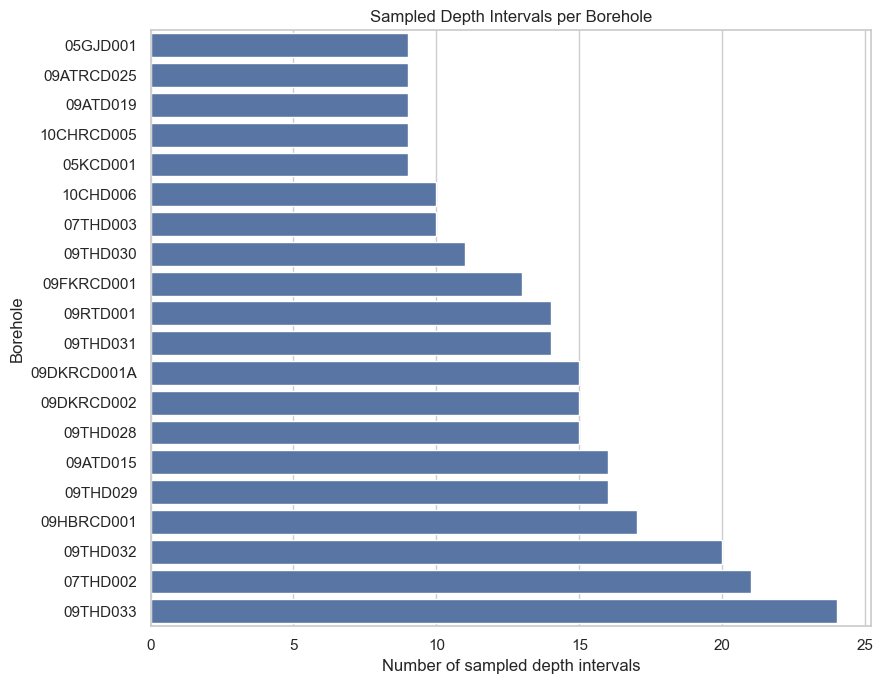

In [10]:
plot_data = coverage.sort_values(
    "intervals",
    ascending=True,
)

fig, ax = plt.subplots(figsize=(9, 7))

sns.barplot(
    data=plot_data,
    x="intervals",
    y="hole_id",
    ax=ax,
)

ax.set_title("Sampled Depth Intervals per Borehole")
ax.set_xlabel("Number of sampled depth intervals")
ax.set_ylabel("Borehole")

plt.tight_layout()
plt.show()

## Actual depth ranges

### Sampled depth coverage

The figure below shows the minimum and maximum sampled depths available for each borehole in the current extract.

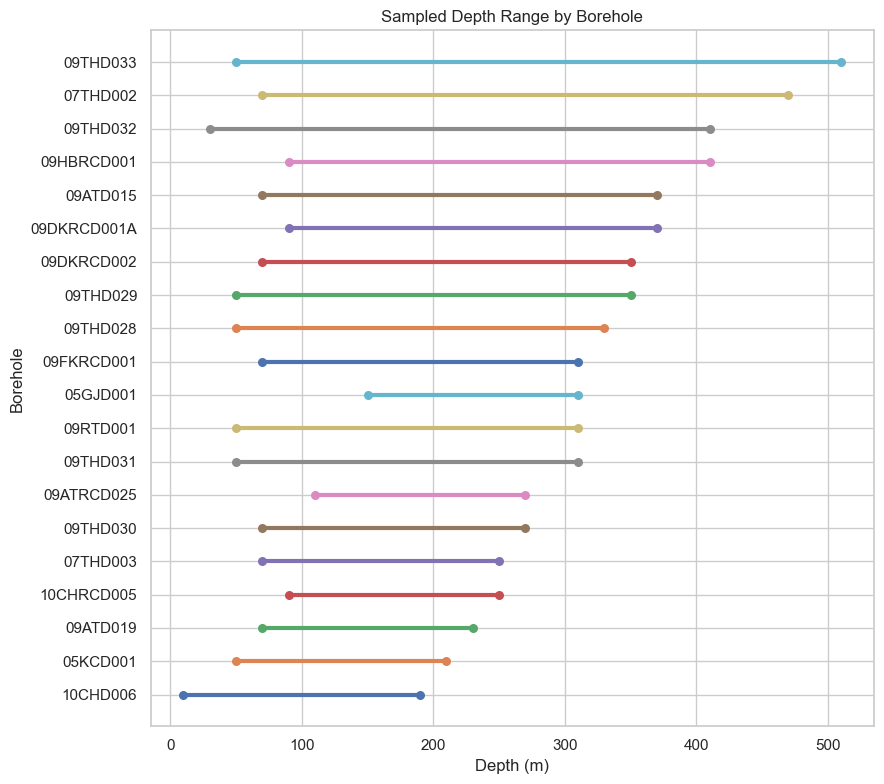

In [11]:
depth_plot = coverage.sort_values(
    "max_depth_m",
    ascending=True,
).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9, 8))

for i, row in depth_plot.iterrows():
    ax.plot(
        [row["min_depth_m"], row["max_depth_m"]],
        [i, i],
        linewidth=3,
    )

    ax.scatter(
        [row["min_depth_m"], row["max_depth_m"]],
        [i, i],
        s=30,
    )

ax.set_yticks(range(len(depth_plot)))
ax.set_yticklabels(depth_plot["hole_id"])

ax.set_xlabel("Depth (m)")
ax.set_ylabel("Borehole")
ax.set_title("Sampled Depth Range by Borehole")

plt.tight_layout()
plt.show()

In [12]:
print("COVERAGE STATISTICS \n")


print("\nIntervals per hole:")
print(coverage["intervals"].describe())

print("\nDepth span per hole:")
print(coverage["depth_span_m"].describe())

max_intervals = coverage["intervals"].max()
min_intervals = coverage["intervals"].min()

print("\nHole(s) with most sampled intervals:")
print(
    coverage.loc[
        coverage["intervals"] == max_intervals,
        ["hole_id", "intervals", "min_depth_m", "max_depth_m", "depth_span_m"]
    ].to_string(index=False)
)

print("\nHole(s) with fewest sampled intervals:")
print(
    coverage.loc[
        coverage["intervals"] == min_intervals,
        ["hole_id", "intervals", "min_depth_m", "max_depth_m", "depth_span_m"]
    ].to_string(index=False)
)

max_span = coverage["depth_span_m"].max()
min_span = coverage["depth_span_m"].min()

print("\nHole(s) with largest sampled depth span:")
print(
    coverage.loc[
        coverage["depth_span_m"] == max_span,
        ["hole_id", "intervals", "min_depth_m", "max_depth_m", "depth_span_m"]
    ].to_string(index=False)
)

print("\nHole(s) with smallest sampled depth span:")
print(
    coverage.loc[
        coverage["depth_span_m"] == min_span,
        ["hole_id", "intervals", "min_depth_m", "max_depth_m", "depth_span_m"]
    ].to_string(index=False)
)

print("\nOverall dataset:")
print(f"Total boreholes:          {coverage['hole_id'].nunique()}")
print(f"Total sampled intervals:  {coverage['intervals'].sum()}")
print(
    f"Overall sampled depth:    "
    f"{pct['depth'].min():.1f}–{pct['depth'].max():.1f} m"
)


COVERAGE STATISTICS 


Intervals per hole:
count    20.00000
mean     13.80000
std       4.42005
min       9.00000
25%       9.75000
50%      14.00000
75%      16.00000
max      24.00000
Name: intervals, dtype: float64

Depth span per hole:
count     20.000
mean     256.000
std       88.401
min      160.000
25%      175.000
50%      260.000
75%      300.000
max      460.000
Name: depth_span_m, dtype: float64

Hole(s) with most sampled intervals:
 hole_id  intervals  min_depth_m  max_depth_m  depth_span_m
09THD033         24         50.0        510.0         460.0

Hole(s) with fewest sampled intervals:
   hole_id  intervals  min_depth_m  max_depth_m  depth_span_m
  05GJD001          9        150.0        310.0         160.0
  05KCD001          9         50.0        210.0         160.0
  09ATD019          9         70.0        230.0         160.0
09ATRCD025          9        110.0        270.0         160.0
10CHRCD005          9         90.0        250.0         160.0

Hole(s) with larg

### Coverage interpretation

The current extract contains 276 sampled depth positions across 20 WA boreholes. Individual holes contain between 9 and 24 sampled intervals, reflecting differences in the depth range available for each borehole rather than inconsistent sampling.

All 256 consecutive depth gaps observed within holes are exactly 20 m, confirming that the current NVCL extract follows the intended 20 m downsampled prototype resolution.

The sampled depth range varies substantially between holes. For example, some holes cover only 160 m of analysed depth, while the longest sampled span is 460 m. This variation should be considered when comparing mineral frequencies or anomaly counts between holes, because longer holes naturally contribute more intervals to the dataset.

The 20 m resolution is suitable for this initial exploratory prototype, but it is much coarser than the native HyLogger measurements. Therefore, conclusions from this notebook describe broad down-hole mineralogical behaviour rather than fine-scale geological contacts. Finer sampling should be evaluated before the transition-detection component is finalised.

## 2. TSA Classification Data Quality

The raw NVCL mineral-classification response contains valid mineral classes as well as quality-related outputs such as `INVALID` and `NOTAROK`.

Quality is examined at two levels:

- **Record-weighted quality:** the proportion of returned classification rows that are flagged.
- **Count-weighted quality:** the proportion of total positive `classCount` associated with flagged rows.

This distinction is important because a flagged record may represent either a very small or a very large share of the returned classification count at a sampled depth.

An interval is not automatically treated as unusable simply because it contains a flagged record. Instead, the analysis checks whether valid mineral information remains and measures how severe the flagged component is.

## Overall quality summary

In [13]:
total_raw_records = len(raw)
total_intervals = len(quality)

flagged_records = quality["flagged_records"].sum()
intervals_with_flags = (quality["flagged_records"] > 0).sum()
intervals_with_valid_data = quality["has_valid_data"].sum()

print("OVERALL DATA QUALITY \n")


print(f"Raw returned records:              {total_raw_records:,}")

print(
    f"Flagged records:                   "
    f"{flagged_records:,} "
    f"({flagged_records / total_raw_records * 100:.2f}%)"
)

print(
    f"Intervals with >=1 flagged record: "
    f"{intervals_with_flags}/{total_intervals} "
    f"({intervals_with_flags / total_intervals * 100:.1f}%)"
)

print(
    f"Intervals retaining valid data:    "
    f"{intervals_with_valid_data}/{total_intervals} "
    f"({intervals_with_valid_data / total_intervals * 100:.1f}%)"
)

print("\nFlagged record types:")
print(
    quality[
        [
            "invalid_label_records",
            "sentinel_records",
            "missing_records",
            "nonpositive_records",
        ]
    ]
    .sum()
    .to_string()
)


OVERALL DATA QUALITY 

Raw returned records:              1,906
Flagged records:                   287 (15.06%)
Intervals with >=1 flagged record: 232/276 (84.1%)
Intervals retaining valid data:    276/276 (100.0%)

Flagged record types:
invalid_label_records    287
sentinel_records           0
missing_records            0
nonpositive_records        0


## Compare record-weighted and count-weighted quality

In [14]:
print("QUALITY SEVERITY DISTRIBUTION \n")


quality_summary = quality[
    [
        "flagged_record_pct",
        "flagged_count_pct",
    ]
].describe()

quality_summary

QUALITY SEVERITY DISTRIBUTION 



,flagged_record_pct,flagged_count_pct
count,276.000000,276.000000
mean,16.664634,23.393984
std,12.251158,31.233992
min,0.000000,0.000000
25%,10.000000,0.124897
50%,14.835165,4.588838
75%,20.000000,46.135236
max,50.000000,96.592292


### Distribution of count-weighted flagged share

The count-weighted metric shows how much of the returned classification count at each sampled depth is associated with flagged outputs. This provides more context than the number of flagged rows alone.

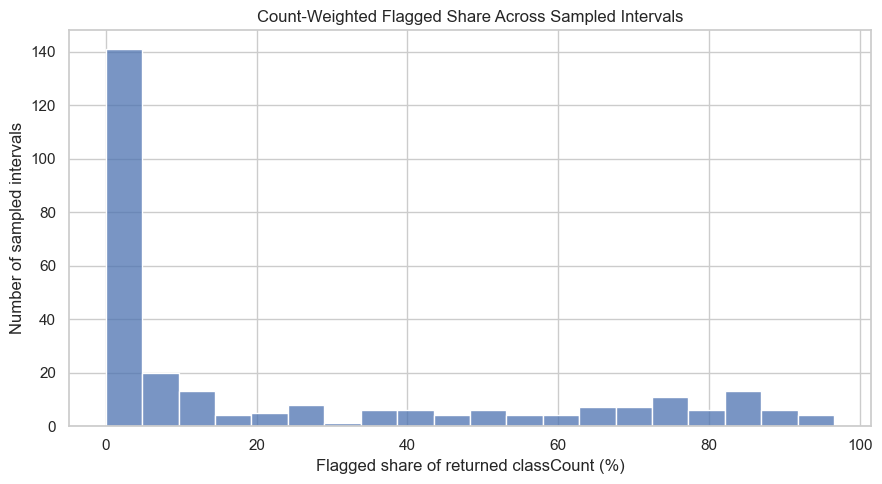

In [15]:
fig, ax = plt.subplots(figsize=(9, 5))

sns.histplot(
    data=quality,
    x="flagged_count_pct",
    bins=20,
    ax=ax,
)

ax.set_title("Count-Weighted Flagged Share Across Sampled Intervals")
ax.set_xlabel("Flagged share of returned classCount (%)")
ax.set_ylabel("Number of sampled intervals")

plt.tight_layout()
plt.show()

In [16]:
highest_flagged = (
    quality
    .sort_values(
        "flagged_count_pct",
        ascending=False,
    )
    [
        [
            "hole_id",
            "depth",
            "returned_records",
            "flagged_records",
            "valid_records",
            "flagged_record_pct",
            "flagged_count_pct",
        ]
    ]
    .head(15)
    .reset_index(drop=True)
)

print("INTERVALS WITH HIGHEST COUNT-WEIGHTED FLAGGED SHARE \n")


highest_flagged

INTERVALS WITH HIGHEST COUNT-WEIGHTED FLAGGED SHARE 



,hole_id,depth,returned_records,flagged_records,valid_records,flagged_record_pct,flagged_count_pct
0,07THD002,230.0,13,2,11,15.384615,96.592292
1,09THD033,210.0,11,2,9,18.181818,96.050269
2,07THD002,210.0,13,1,12,7.692308,94.482481
3,07THD002,270.0,15,2,13,13.333333,91.900043
4,07THD002,290.0,12,2,10,16.666667,89.456011
5,07THD002,250.0,13,2,11,15.384615,89.248895
6,09THD033,130.0,11,2,9,18.181818,88.559814
7,10CHD006,150.0,11,1,10,9.090909,88.499763
8,10CHD006,90.0,10,1,9,10.000000,87.917620
9,07THD002,190.0,13,2,11,15.384615,87.026066


### Data quality by borehole

Quality is also summarised by borehole to determine whether flagged classifications are concentrated in particular holes or distributed relatively evenly across the dataset.

In [17]:
quality_by_hole = (
    quality.groupby("hole_id")
    .agg(
        intervals=("depth", "size"),
        intervals_with_flags=(
            "flagged_records",
            lambda x: (x > 0).sum(),
        ),
        mean_flagged_record_pct=(
            "flagged_record_pct",
            "mean",
        ),
        median_flagged_count_pct=(
            "flagged_count_pct",
            "median",
        ),
        mean_flagged_count_pct=(
            "flagged_count_pct",
            "mean",
        ),
        max_flagged_count_pct=(
            "flagged_count_pct",
            "max",
        ),
    )
    .reset_index()
)

quality_by_hole["intervals_with_flags_pct"] = (
    quality_by_hole["intervals_with_flags"]
    / quality_by_hole["intervals"]
    * 100
)

quality_by_hole.sort_values(
    "mean_flagged_count_pct",
    ascending=False,
)

,hole_id,intervals,intervals_with_flags,mean_flagged_record_pct,median_flagged_count_pct,mean_flagged_count_pct,max_flagged_count_pct,intervals_with_flags_pct
17,09THD033,24,22,14.613511,68.865190,61.367021,96.050269,91.666667
18,10CHD006,10,10,10.297980,81.536928,61.053168,88.499763,100.000000
10,09HBRCD001,17,16,13.321662,49.134487,47.512347,83.371092,94.117647
3,07THD003,10,10,14.053030,49.122014,46.762537,77.360877,100.000000
2,07THD002,21,20,16.348651,45.429741,45.534274,96.592292,95.238095
16,09THD032,20,17,29.916667,4.811380,22.445417,77.910448,85.000000
1,05KCD001,9,9,12.376543,14.853672,20.369159,51.515152,100.000000
13,09THD029,16,12,17.991332,0.198509,18.990142,78.548896,75.000000
8,09DKRCD002,15,13,18.062345,0.922671,17.433501,82.562855,86.666667
12,09THD028,15,10,18.390313,0.178333,17.269590,73.114754,66.666667


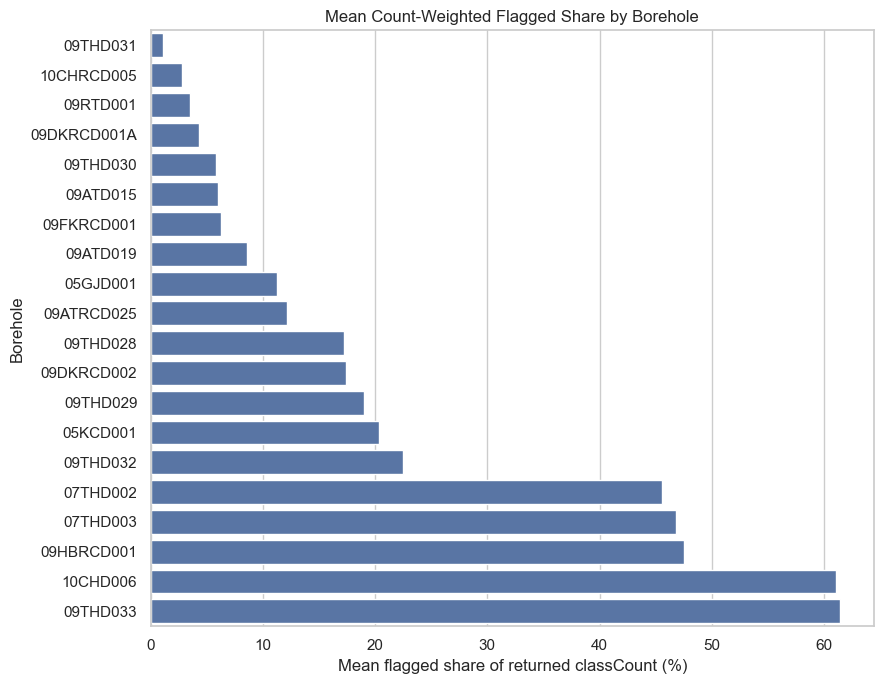

In [18]:
plot_quality = quality_by_hole.sort_values(
    "mean_flagged_count_pct",
    ascending=True,
)

fig, ax = plt.subplots(figsize=(9, 7))

sns.barplot(
    data=plot_quality,
    x="mean_flagged_count_pct",
    y="hole_id",
    ax=ax,
)

ax.set_title("Mean Count-Weighted Flagged Share by Borehole")
ax.set_xlabel("Mean flagged share of returned classCount (%)")
ax.set_ylabel("Borehole")

plt.tight_layout()
plt.show()

In [19]:
print("DATA QUALITY — CLIENT MEETING SUMMARY \n")


print(
    f"1. Flagged raw records: "
    f"{flagged_records}/{total_raw_records} "
    f"({flagged_records / total_raw_records * 100:.2f}%)"
)

print(
    f"2. Intervals containing at least one flagged record: "
    f"{intervals_with_flags}/{total_intervals} "
    f"({intervals_with_flags / total_intervals * 100:.1f}%)"
)

print(
    f"3. Intervals retaining valid mineral information: "
    f"{intervals_with_valid_data}/{total_intervals} "
    f"({intervals_with_valid_data / total_intervals * 100:.1f}%)"
)

print(
    f"4. Median count-weighted flagged share: "
    f"{quality['flagged_count_pct'].median():.2f}%"
)

print(
    f"5. Maximum count-weighted flagged share: "
    f"{quality['flagged_count_pct'].max():.2f}%"
)



DATA QUALITY — CLIENT MEETING SUMMARY 

1. Flagged raw records: 287/1906 (15.06%)
2. Intervals containing at least one flagged record: 232/276 (84.1%)
3. Intervals retaining valid mineral information: 276/276 (100.0%)
4. Median count-weighted flagged share: 4.59%
5. Maximum count-weighted flagged share: 96.59%


### Data-quality interpretation

The raw uTSAS extract contains 1,906 returned classification records, of which 287 (15.06%) are flagged as `INVALID` or `NOTAROK`. No sentinel, missing, or non-positive count records were observed in this extract.

Although 232 of 276 sampled depth intervals (84.1%) contain at least one flagged classification, every interval still retains valid mineral information. Therefore, it would be misleading to describe 84.1% of the sampled intervals as unusable.

The severity of the flagged component varies considerably between intervals. The median count-weighted flagged share is only 4.59%, but the maximum reaches 96.59%. This indicates a strongly skewed quality distribution: many intervals contain only a small flagged component, while a smaller number are dominated by flagged classification counts.

The most severe intervals are concentrated in several boreholes, particularly `07THD002`, `09THD033`, and `10CHD006`. Mean count-weighted flagged share also varies substantially between boreholes, suggesting that data quality should be considered explicitly when comparing holes or using individual intervals in later modelling.

A useful question for GSWA is what level of flagged TSA output should cause an interval to be treated as low-confidence, excluded from modelling, or sent for expert review. No threshold is imposed here because that decision requires geological/domain guidance.

## 3. Wt1 Confidence Analysis

`Wt1 uTSAS` is a continuous numeric output associated with the uTSAS mineral interpretation.

One question identified during project planning was whether values such as `Wt1 = 1.0` represent genuine maximum confidence or may instead be a default/placeholder value.

This section examines:

- Wt1 coverage across the current 20-hole extract;
- the overall Wt1 distribution;
- how often Wt1 is exactly 1.0;
- variation between boreholes; and
- variation with depth in the first five detailed EDA holes.

The analysis describes the current sampled dataset only. Interpretation of the geological meaning of Wt1 should still be confirmed with GSWA.

## Overall Summary

In [20]:
wt1_values = pd.to_numeric(
    wt1["wt1"],
    errors="coerce",
)

valid_wt1 = wt1_values.dropna()

exactly_one = np.isclose(
    valid_wt1,
    1.0,
    rtol=0,
    atol=1e-12,
).sum()

print("WT1 uTSAS SUMMARY \n")

print(f"Total sampled intervals: {len(wt1):,}")
print(f"Holes represented:       {wt1['hole_id'].nunique()}")
print(f"Missing Wt1 values:      {wt1_values.isna().sum()}")
print(
    f"Exactly 1.0:             "
    f"{exactly_one}/{len(valid_wt1)} "
    f"({exactly_one / len(valid_wt1) * 100:.2f}%)"
)

print("\nWt1 distribution:")
print(valid_wt1.describe())


WT1 uTSAS SUMMARY 

Total sampled intervals: 276
Holes represented:       20
Missing Wt1 values:      0
Exactly 1.0:             0/276 (0.00%)

Wt1 distribution:
count    276.000000
mean       0.837821
std        0.115026
min        0.501382
25%        0.740193
50%        0.869390
75%        0.933805
max        0.997208
Name: wt1, dtype: float64


## Overall Wt1 distribution

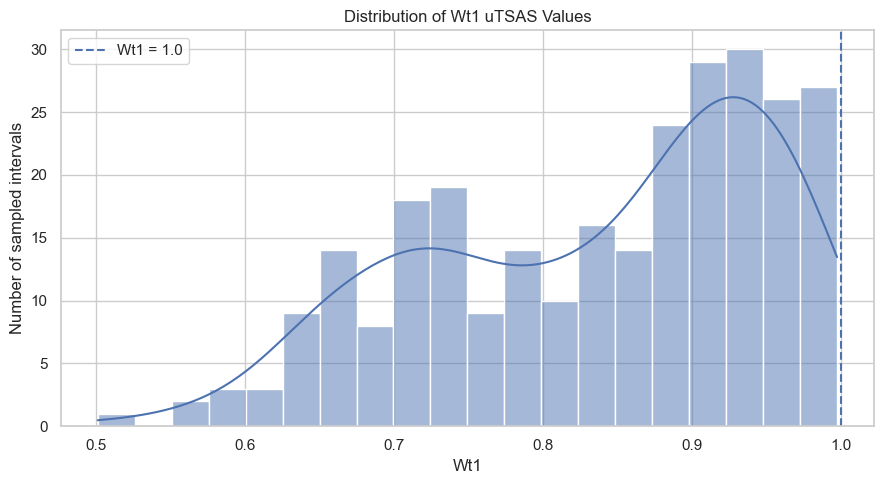

In [21]:
fig, ax = plt.subplots(figsize=(9, 5))

sns.histplot(
    data=wt1,
    x="wt1",
    bins=20,
    kde=True,
    ax=ax,
)

ax.axvline(
    1.0,
    linestyle="--",
    linewidth=1.5,
    label="Wt1 = 1.0",
)

ax.set_title("Distribution of Wt1 uTSAS Values")
ax.set_xlabel("Wt1")
ax.set_ylabel("Number of sampled intervals")
ax.legend()

plt.tight_layout()
plt.show()

## Wt1 variation between boreholes

If Wt1 represents a meaningful varying output, its distribution may differ between boreholes rather than remaining constant across the dataset.

In [22]:
wt1_by_hole = (
    wt1.groupby("hole_id")["wt1"]
    .agg(
        observations="count",
        minimum="min",
        mean="mean",
        median="median",
        maximum="max",
        std="std",
    )
    .reset_index()
)

wt1_by_hole.sort_values(
    "mean",
    ascending=False,
)

,hole_id,observations,minimum,mean,median,maximum,std
17,09THD033,24,0.805886,0.928015,0.933184,0.990758,0.044075
16,09THD032,20,0.658396,0.906680,0.933284,0.994081,0.073880
2,07THD002,21,0.688084,0.906637,0.945068,0.993281,0.091855
3,07THD003,10,0.815720,0.905980,0.914655,0.989891,0.061337
18,10CHD006,10,0.641411,0.895024,0.977831,0.989407,0.142893
13,09THD029,16,0.599276,0.890979,0.938344,0.997208,0.124320
15,09THD031,14,0.667728,0.878850,0.905090,0.946249,0.082485
5,09ATD019,9,0.747380,0.878193,0.878971,0.979459,0.070119
12,09THD028,15,0.553839,0.868919,0.917107,0.974155,0.123839
10,09HBRCD001,17,0.654530,0.863282,0.898048,0.955732,0.100240


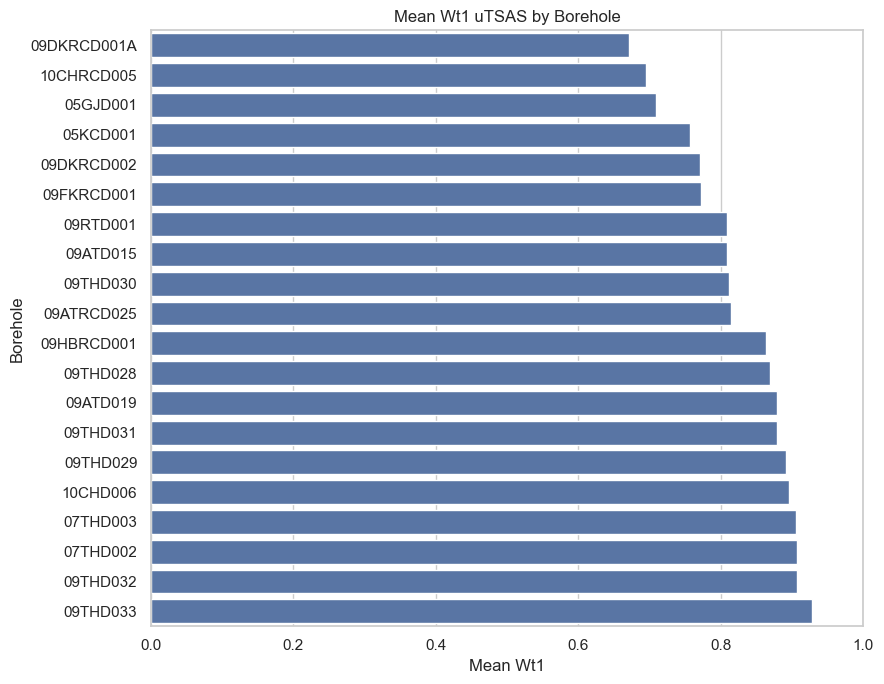

In [23]:
plot_wt1 = wt1_by_hole.sort_values(
    "mean",
    ascending=True,
)

fig, ax = plt.subplots(figsize=(9, 7))

sns.barplot(
    data=plot_wt1,
    x="mean",
    y="hole_id",
    ax=ax,
)

ax.set_xlim(0, 1)
ax.set_title("Mean Wt1 uTSAS by Borehole")
ax.set_xlabel("Mean Wt1")
ax.set_ylabel("Borehole")

plt.tight_layout()
plt.show()

## Wt1 variation with depth in the first five holes

Wt1 is plotted against depth for the five boreholes selected for detailed EDA. Depth increases downward to match conventional down-hole visualisation.

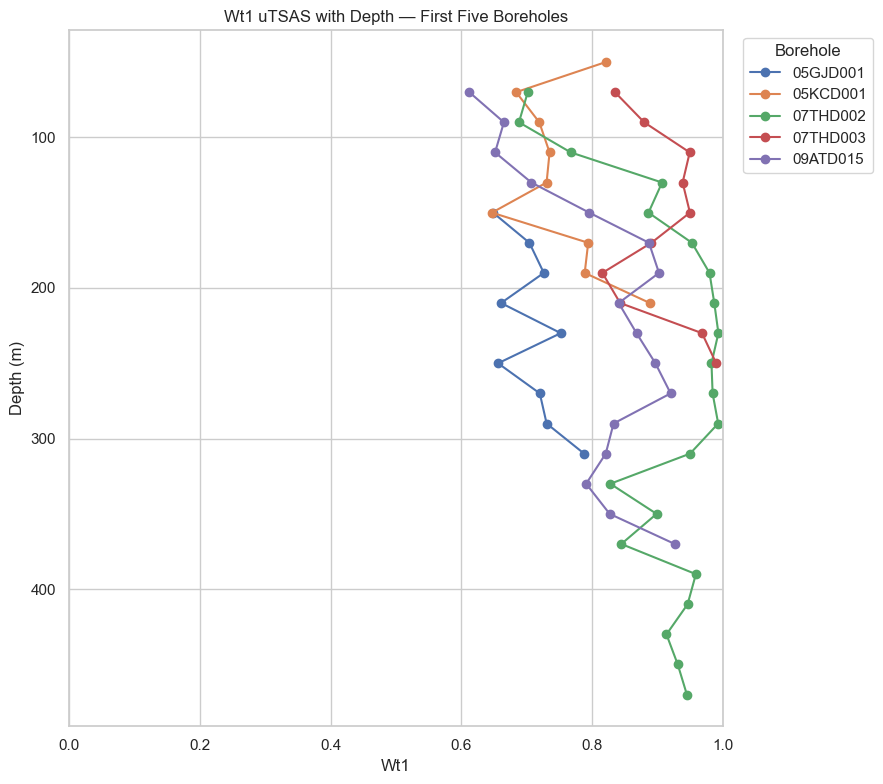

In [24]:
first_five_wt1 = wt1[
    wt1["hole_id"].isin(eda_holes)
].copy()

fig, ax = plt.subplots(figsize=(9, 8))

for hole_id in eda_holes:
    sub = (
        first_five_wt1[
            first_five_wt1["hole_id"] == hole_id
        ]
        .sort_values("depth")
    )

    ax.plot(
        sub["wt1"],
        sub["depth"],
        marker="o",
        label=hole_id,
    )

ax.invert_yaxis()

ax.set_xlim(0, 1)
ax.set_xlabel("Wt1")
ax.set_ylabel("Depth (m)")
ax.set_title("Wt1 uTSAS with Depth — First Five Boreholes")

ax.legend(
    title="Borehole",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

plt.tight_layout()
plt.show()

In [25]:
print("WT1 — SUMMARY \n")


print(
    f"1. Wt1 coverage: "
    f"{valid_wt1.count()}/{len(wt1)} intervals "
    f"({valid_wt1.count() / len(wt1) * 100:.1f}%)"
)

print(
    f"2. Wt1 exactly equal to 1.0: "
    f"{exactly_one}/{len(valid_wt1)} "
    f"({exactly_one / len(valid_wt1) * 100:.2f}%)"
)

print(
    f"3. Wt1 range: "
    f"{valid_wt1.min():.3f}–{valid_wt1.max():.3f}"
)

print(
    f"4. Mean Wt1: "
    f"{valid_wt1.mean():.3f}"
)

print(
    f"5. Median Wt1: "
    f"{valid_wt1.median():.3f}"
)



WT1 — SUMMARY 

1. Wt1 coverage: 276/276 intervals (100.0%)
2. Wt1 exactly equal to 1.0: 0/276 (0.00%)
3. Wt1 range: 0.501–0.997
4. Mean Wt1: 0.838
5. Median Wt1: 0.869


### Wt1 interpretation

Wt1 is available for all 276 sampled intervals in the current 20-hole extract, with no missing values. Values range from approximately 0.501 to 0.997, with a mean of 0.838 and a median of 0.869.

None of the observed Wt1 values are exactly equal to 1.0. Therefore, the suspected behaviour in which `Wt1 = 1.0` might act as a constant/default placeholder is not observed in this dataset.

Wt1 also varies both between boreholes and with depth within individual holes. Mean values differ noticeably between holes, while the first-five depth profiles show repeated within-hole changes rather than constant values. This is consistent with Wt1 behaving as a varying numeric output rather than a fixed field.

These findings do not establish the geological interpretation of Wt1. GSWA should still confirm what Wt1 formally represents and how it should be used when communicating confidence or filtering intervals.

## 4. Mineral Distribution and Classifier Feature Availability

The modelling-ready uTSAS dataset contains mineral percentages for all valid mineral groups returned at each sampled depth.

This section examines:

- how frequently each mineral group occurs across the 276 sampled intervals;
- how abundant each mineral is when it is present;
- which minerals dominate the current uTSAS dataset; and
- whether the mineral inputs required by the baseline rule classifier are actually available in this TSA product.

This check is important before applying rule thresholds or training later models, because a mineral that is absent from the selected TSA product should not automatically be interpreted as having zero geological abundance.

In [26]:
mineral_summary = []

for mineral in mineral_cols:
    values = pct[mineral]

    present = values > 0
    present_values = values[present]

    mineral_summary.append(
        {
            "mineral": mineral,
            "intervals_present": int(present.sum()),
            "prevalence_pct": present.mean() * 100,
            "mean_pct_all_intervals": values.mean(),
            "mean_pct_when_present": (
                present_values.mean()
                if len(present_values)
                else np.nan
            ),
            "median_pct_when_present": (
                present_values.median()
                if len(present_values)
                else np.nan
            ),
            "max_pct": values.max(),
        }
    )

mineral_summary = pd.DataFrame(mineral_summary)

mineral_summary = mineral_summary.sort_values(
    "prevalence_pct",
    ascending=False,
).reset_index(drop=True)

print("MINERAL PREVALENCE AND ABUNDANCE \n")

mineral_summary

MINERAL PREVALENCE AND ABUNDANCE 



,mineral,intervals_present,prevalence_pct,mean_pct_all_intervals,mean_pct_when_present,median_pct_when_present,max_pct
0,WHITE-MICA,239,86.594203,32.043472,37.004177,12.328767,100.000000
1,CHLORITE,212,76.811594,43.004510,55.987004,56.681951,100.000000
2,CARBONATE,198,71.739130,7.081862,9.871686,4.528198,75.000000
3,DARK-MICA,143,51.811594,3.899800,7.526886,2.793792,76.475096
4,AMPHIBOLE,137,49.637681,5.311019,10.699572,4.731861,62.926224
5,EPIDOTE,134,48.550725,2.121458,4.369570,1.091378,66.954023
6,SMECTITE,125,45.289855,1.955548,4.317850,1.090188,50.000000
7,SULPHATE,99,35.869565,0.553286,1.542496,0.505051,21.400778
8,OTHER-ALOH,86,31.159420,0.654222,2.099595,0.777530,19.214703
9,KAOLIN,69,25.000000,0.158540,0.634160,0.230592,4.892368


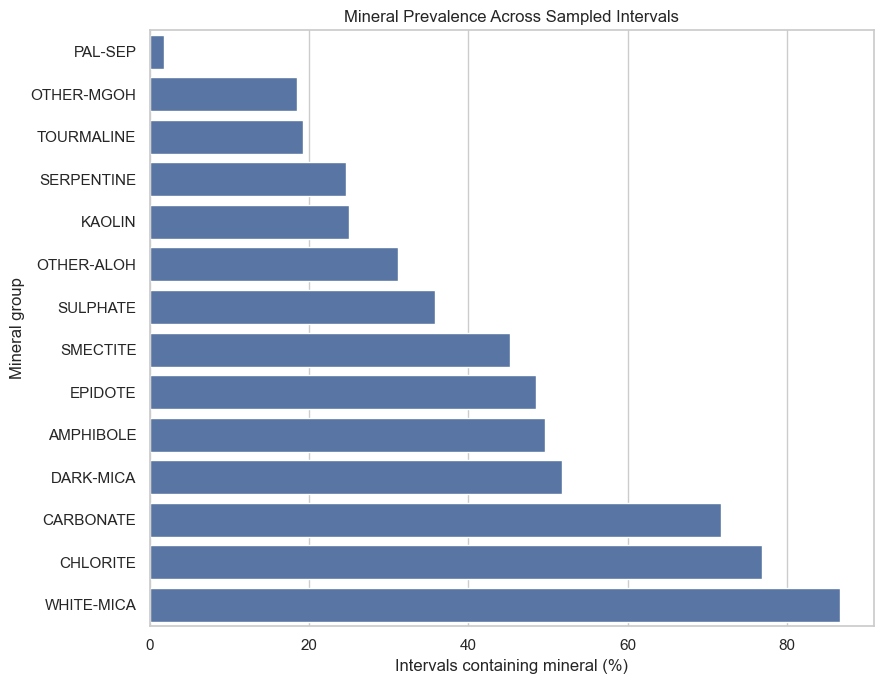

In [27]:
plot_minerals = mineral_summary.sort_values(
    "prevalence_pct",
    ascending=True,
)

fig, ax = plt.subplots(figsize=(9, 7))

sns.barplot(
    data=plot_minerals,
    x="prevalence_pct",
    y="mineral",
    ax=ax,
)

ax.set_title("Mineral Prevalence Across Sampled Intervals")
ax.set_xlabel("Intervals containing mineral (%)")
ax.set_ylabel("Mineral group")

plt.tight_layout()
plt.show()

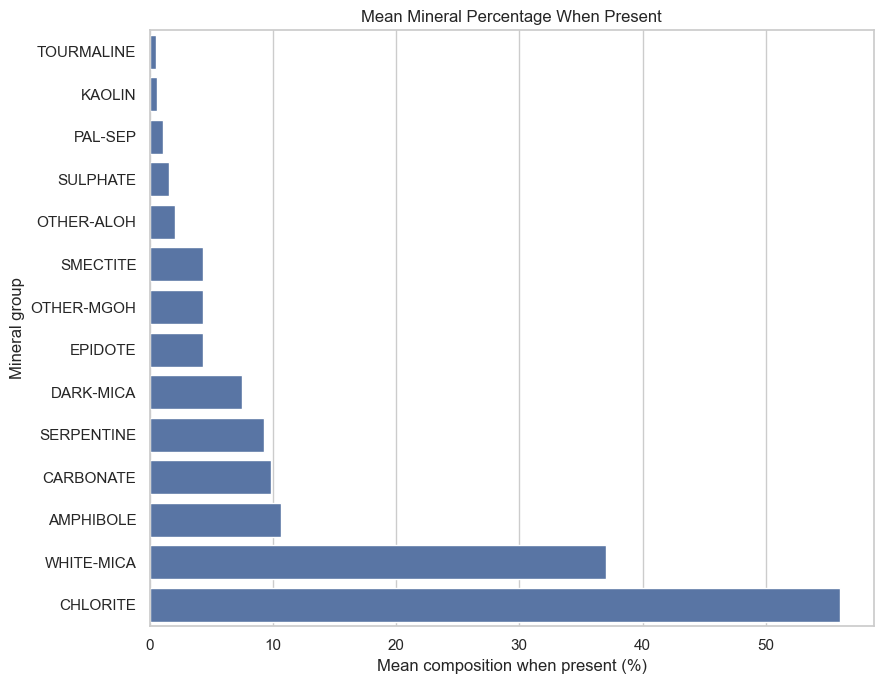

In [28]:
abundance_plot = mineral_summary.sort_values(
    "mean_pct_when_present",
    ascending=True,
)

fig, ax = plt.subplots(figsize=(9, 7))

sns.barplot(
    data=abundance_plot,
    x="mean_pct_when_present",
    y="mineral",
    ax=ax,
)

ax.set_title("Mean Mineral Percentage When Present")
ax.set_xlabel("Mean composition when present (%)")
ax.set_ylabel("Mineral group")

plt.tight_layout()
plt.show()

In [29]:
classifier_minerals = [
    "WHITE-MICA",
    "CHLORITE",
    "HEMATITE",
    "KAOLIN",
    "GOETHITE",
]

classifier_feature_check = pd.DataFrame(
    {
        "mineral": classifier_minerals,
        "available_in_utsas": [
            mineral in mineral_cols
            for mineral in classifier_minerals
        ],
    }
)

prevalence_lookup = (
    mineral_summary
    .set_index("mineral")["prevalence_pct"]
    .to_dict()
)

classifier_feature_check["prevalence_pct"] = (
    classifier_feature_check["mineral"]
    .map(prevalence_lookup)
)

print("BASELINE CLASSIFIER FEATURE AVAILABILITY \n")


classifier_feature_check

BASELINE CLASSIFIER FEATURE AVAILABILITY 



,mineral,available_in_utsas,prevalence_pct
0,WHITE-MICA,True,86.594203
1,CHLORITE,True,76.811594
2,HEMATITE,False,NaN
3,KAOLIN,True,25.000000
4,GOETHITE,False,NaN


In [30]:
available_features = classifier_feature_check.loc[
    classifier_feature_check["available_in_utsas"],
    "mineral",
].tolist()

missing_features = classifier_feature_check.loc[
    ~classifier_feature_check["available_in_utsas"],
    "mineral",
].tolist()

print("CLASSIFIER COMPATIBILITY SUMMARY \n")

print(
    f"Required classifier minerals: "
    f"{len(classifier_minerals)}"
)

print(
    f"Available in Grp1 uTSAS:      "
    f"{len(available_features)}"
)

print(
    f"Unavailable in Grp1 uTSAS:    "
    f"{len(missing_features)}"
)

print("\nAvailable:")
for mineral in available_features:
    print(f"  {mineral}")

print("\nNot present as uTSAS mineral columns:")
for mineral in missing_features:
    print(f"  {mineral}")


CLASSIFIER COMPATIBILITY SUMMARY 

Required classifier minerals: 5
Available in Grp1 uTSAS:      3
Unavailable in Grp1 uTSAS:    2

Available:
  WHITE-MICA
  CHLORITE
  KAOLIN

Not present as uTSAS mineral columns:
  HEMATITE
  GOETHITE


### Mineral-distribution interpretation

Fourteen valid mineral groups are present in the current `Grp1 uTSAS` percentage matrix.

`WHITE-MICA`, `CHLORITE`, and `CARBONATE` are the most widespread mineral groups, occurring in approximately 86.6%, 76.8%, and 71.7% of sampled intervals respectively. Prevalence and abundance are not equivalent: for example, when `CHLORITE` is present it contributes an average of approximately 56% of the valid mineral composition, compared with approximately 37% for `WHITE-MICA`.

Some mineral groups are much less common. `PAL-SEP`, for example, occurs in only around 1.8% of sampled intervals. These differences suggest that later anomaly and similarity methods should account for the strongly uneven frequency of mineral groups.

The current baseline classifier expects five mineral inputs: `WHITE-MICA`, `CHLORITE`, `HEMATITE`, `KAOLIN`, and `GOETHITE`. Only three of these five are available as columns in the current `Grp1 uTSAS` dataset. `HEMATITE` and `GOETHITE` are not present in this SWIR-derived mineral-group product.

This should not be interpreted as evidence that hematite or goethite are geologically absent from the boreholes. Instead, the current classifier and the selected TSA product are not fully aligned. Other NVCL spectral products should be investigated before the classifier treats these unavailable features as zero abundance.

## 5. Mineral Composition with Depth

The first five retrieved boreholes are examined in more detail to determine how uTSAS mineral composition changes down-hole.

Because fourteen mineral groups are available, plotting every mineral simultaneously can obscure the main patterns. The analysis therefore:

- identifies the minerals contributing the greatest average abundance across the first five holes;
- visualises these mineral percentages with depth; and
- examines changes in the dominant mineral between consecutive sampled intervals.

Depth increases downward in the following figures to match conventional down-hole visualisation.

The current 20 m sampling resolution captures broad mineralogical changes only. Fine-scale geological boundaries may not be visible at this resolution.

In [31]:
first_five_pct = pct[
    pct["hole_id"].isin(eda_holes)
].copy()

first_five_mean = (
    first_five_pct[mineral_cols]
    .mean()
    .sort_values(ascending=False)
)

print("MEAN MINERAL COMPOSITION — FIRST FIVE HOLES \n")


print(first_five_mean.to_string())

TOP_N_MINERALS = 6

top_minerals = (
    first_five_mean
    .head(TOP_N_MINERALS)
    .index
    .tolist()
)

print(
    f"\nTop {TOP_N_MINERALS} mineral groups "
    "used for detailed depth plots:"
)

for mineral in top_minerals:
    print(f"  {mineral}")

MEAN MINERAL COMPOSITION — FIRST FIVE HOLES 

CHLORITE      43.285009
WHITE-MICA    32.902259
CARBONATE      8.697697
AMPHIBOLE      4.142539
DARK-MICA      3.162259
OTHER-ALOH     2.078870
SMECTITE       1.936662
SULPHATE       1.407751
EPIDOTE        1.086735
KAOLIN         0.441796
OTHER-MGOH     0.398281
TOURMALINE     0.267277
SERPENTINE     0.192865
PAL-SEP        0.000000

Top 6 mineral groups used for detailed depth plots:
  CHLORITE
  WHITE-MICA
  CARBONATE
  AMPHIBOLE
  DARK-MICA
  OTHER-ALOH


## Major mineral percentages with depth

The six mineral groups with the highest mean percentage across the first-five subset are plotted separately for each borehole.

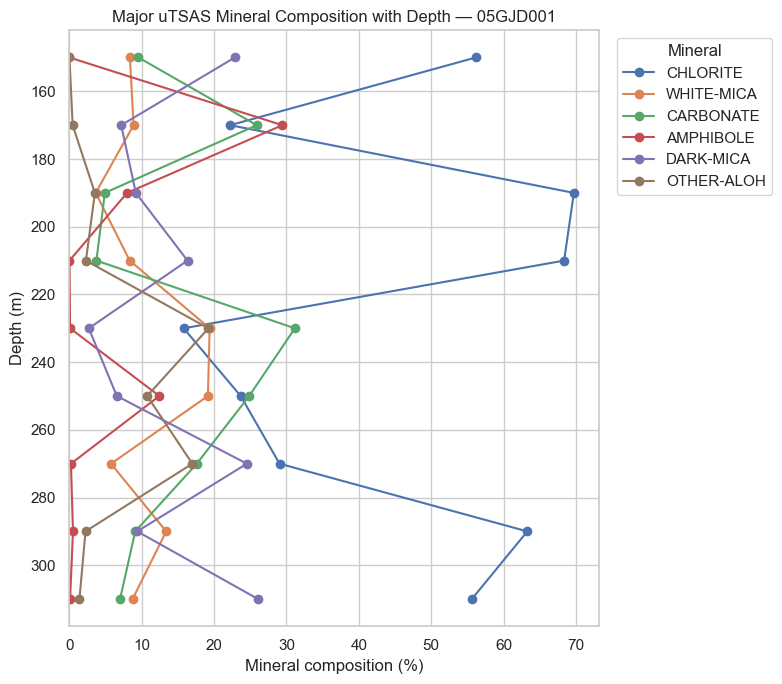

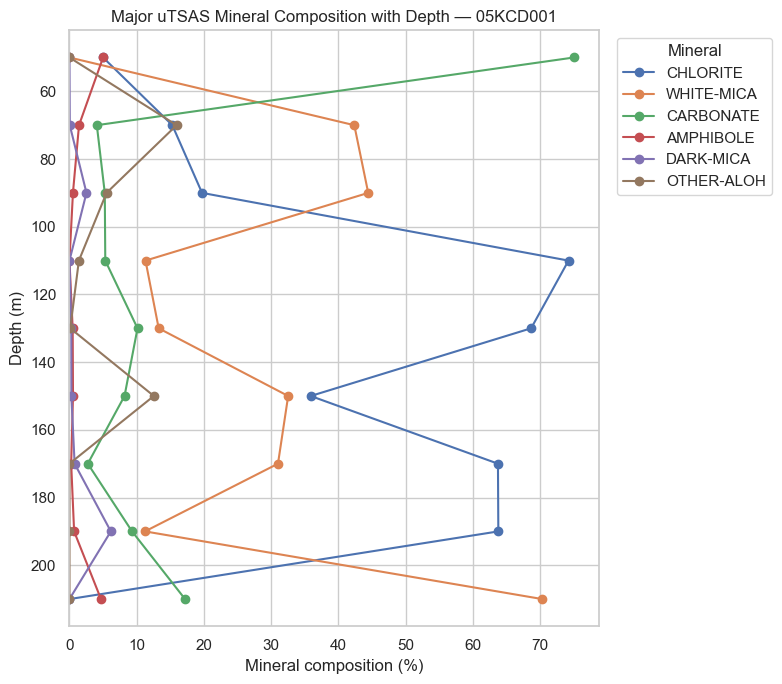

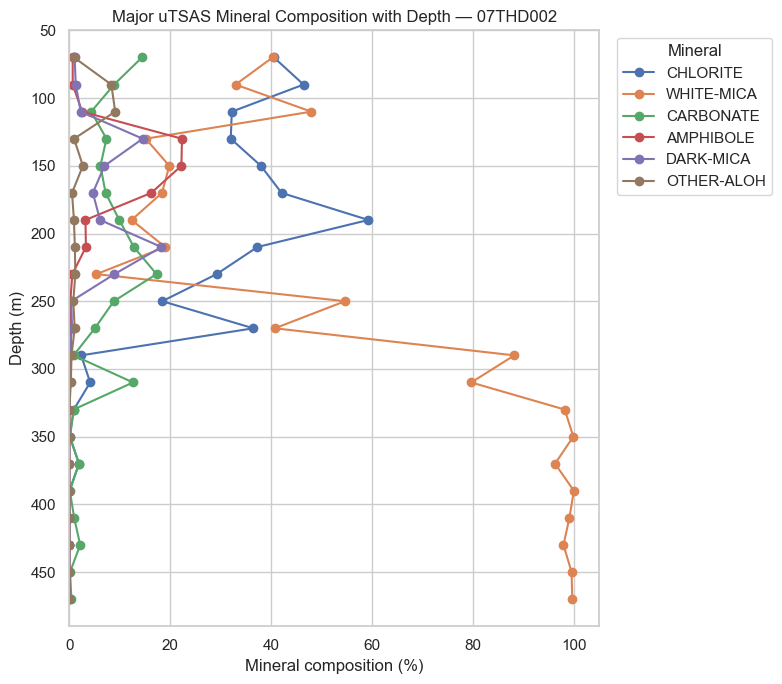

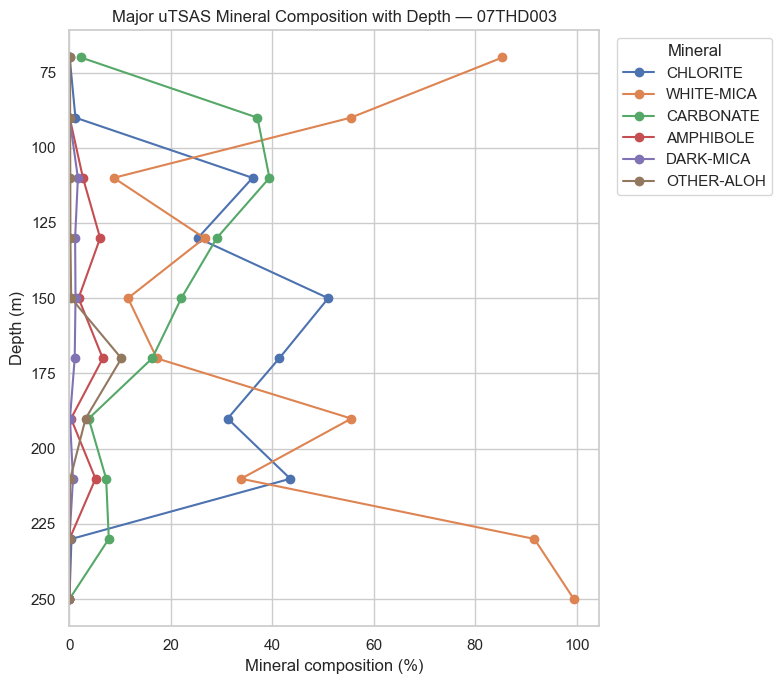

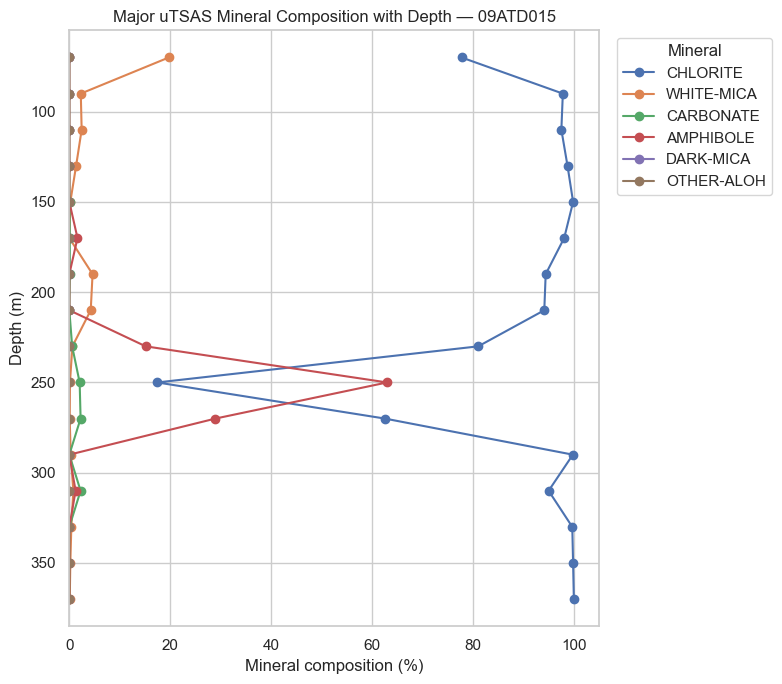

In [32]:
for hole_id in eda_holes:
    hole = (
        first_five_pct[
            first_five_pct["hole_id"] == hole_id
        ]
        .sort_values("depth")
    )

    fig, ax = plt.subplots(figsize=(8, 7))

    for mineral in top_minerals:
        ax.plot(
            hole[mineral],
            hole["depth"],
            marker="o",
            label=mineral,
        )

    ax.invert_yaxis()

    ax.set_xlim(left=0)
    ax.set_xlabel("Mineral composition (%)")
    ax.set_ylabel("Depth (m)")
    ax.set_title(
        f"Major uTSAS Mineral Composition with Depth — {hole_id}"
    )

    ax.legend(
        title="Mineral",
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
    )

    plt.tight_layout()
    plt.show()

## Mineral-composition heatmaps

The same major mineral groups are shown as depth-indexed heatmaps. Higher values indicate a larger percentage contribution at that sampled depth.

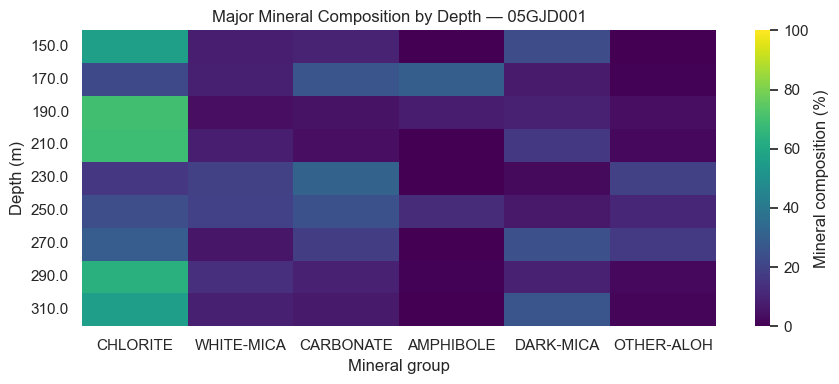

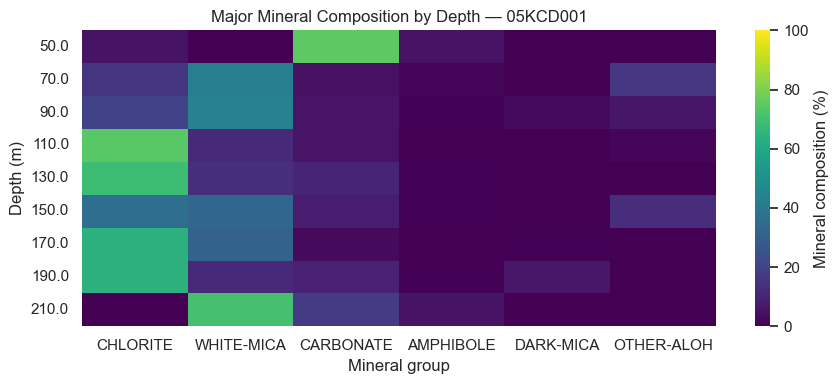

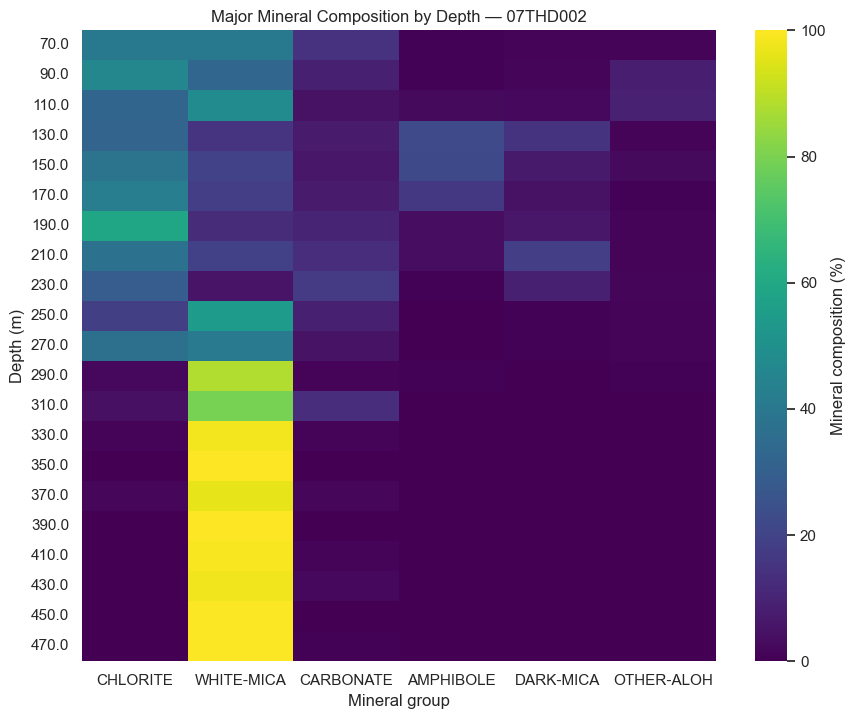

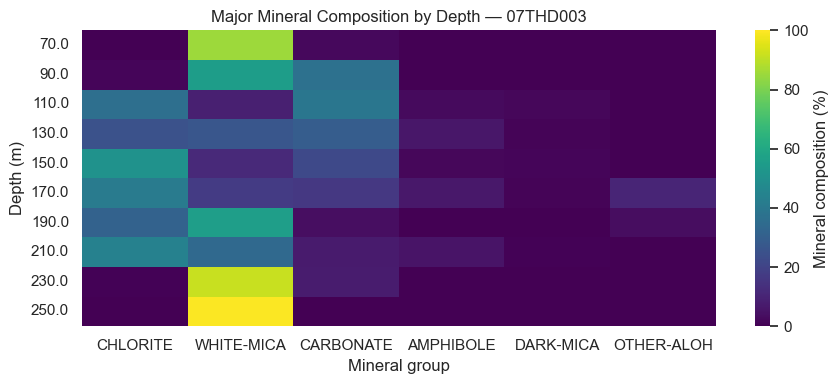

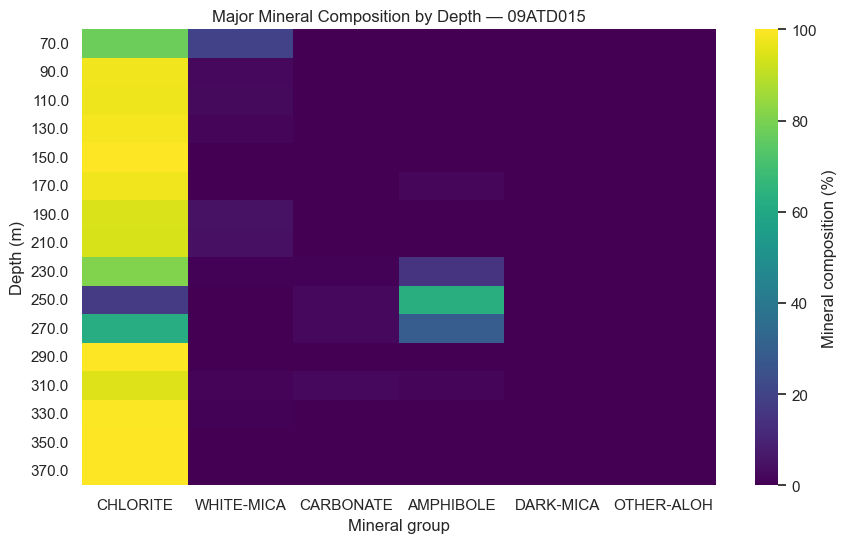

In [33]:
for hole_id in eda_holes:
    hole = (
        first_five_pct[
            first_five_pct["hole_id"] == hole_id
        ]
        .sort_values("depth")
        .set_index("depth")
    )

    heatmap_data = hole[top_minerals]

    fig, ax = plt.subplots(
        figsize=(9, max(4, len(heatmap_data) * 0.35))
    )

    sns.heatmap(
        heatmap_data,
        cmap="viridis",
        vmin=0,
        vmax=100,
        ax=ax,
        cbar_kws={
            "label": "Mineral composition (%)"
        },
    )

    ax.set_title(
        f"Major Mineral Composition by Depth — {hole_id}"
    )

    ax.set_xlabel("Mineral group")
    ax.set_ylabel("Depth (m)")

    plt.tight_layout()
    plt.show()

In [34]:
dominant = first_five_pct[
    ["hole_id", "depth"] + mineral_cols
].copy()

dominant["dominant_mineral"] = (
    dominant[mineral_cols]
    .idxmax(axis=1)
)

dominant["dominant_pct"] = (
    dominant[mineral_cols]
    .max(axis=1)
)

print("DOMINANT MINERAL — FIRST FIVE HOLES \n")

dominant[
    [
        "hole_id",
        "depth",
        "dominant_mineral",
        "dominant_pct",
    ]
].head(20)

DOMINANT MINERAL — FIRST FIVE HOLES 



,hole_id,depth,dominant_mineral,dominant_pct
0,05GJD001,150.0,CHLORITE,56.183746
1,05GJD001,170.0,AMPHIBOLE,29.430380
2,05GJD001,190.0,CHLORITE,69.725275
3,05GJD001,210.0,CHLORITE,68.377724
4,05GJD001,230.0,CARBONATE,31.161236
5,05GJD001,250.0,CARBONATE,24.846111
6,05GJD001,270.0,CHLORITE,29.040534
7,05GJD001,290.0,CHLORITE,63.291825
8,05GJD001,310.0,CHLORITE,55.613126
9,05KCD001,50.0,CARBONATE,75.000000


In [35]:
dominant_summary = (
    dominant["dominant_mineral"]
    .value_counts()
    .rename_axis("mineral")
    .reset_index(name="intervals")
)

dominant_summary["percentage_of_intervals"] = (
    dominant_summary["intervals"]
    / len(dominant)
    * 100
)

dominant_summary

,mineral,intervals,percentage_of_intervals
0,CHLORITE,37,56.923077
1,WHITE-MICA,21,32.307692
2,CARBONATE,5,7.692308
3,AMPHIBOLE,2,3.076923


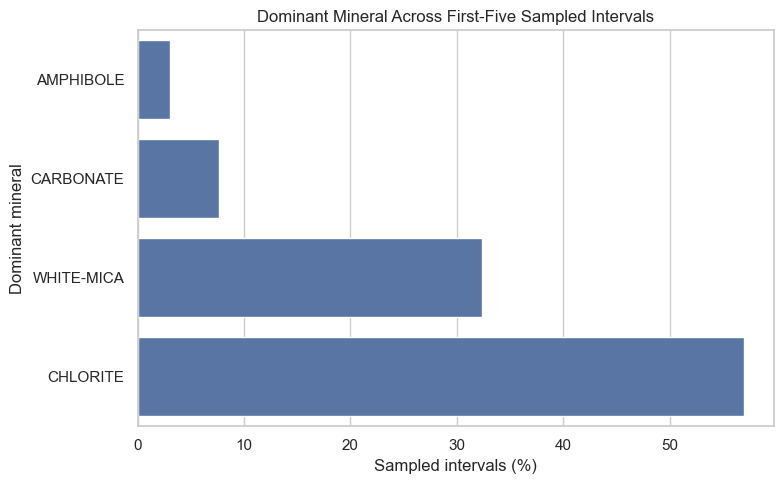

In [36]:
plot_dominant = dominant_summary.sort_values(
    "percentage_of_intervals",
    ascending=True,
)

fig, ax = plt.subplots(figsize=(8, 5))

sns.barplot(
    data=plot_dominant,
    x="percentage_of_intervals",
    y="mineral",
    ax=ax,
)

ax.set_title(
    "Dominant Mineral Across First-Five Sampled Intervals"
)

ax.set_xlabel("Sampled intervals (%)")
ax.set_ylabel("Dominant mineral")

plt.tight_layout()
plt.show()

In [37]:
transition_rows = []

for hole_id, group in dominant.groupby("hole_id"):
    group = (
        group
        .sort_values("depth")
        .reset_index(drop=True)
    )

    previous = group["dominant_mineral"].shift(1)

    changed = (
        group["dominant_mineral"] != previous
    )

    changed.iloc[0] = False

    for idx in group.index[changed]:
        transition_rows.append(
            {
                "hole_id": hole_id,
                "depth_m": group.loc[idx, "depth"],
                "from_mineral": previous.loc[idx],
                "to_mineral": group.loc[
                    idx,
                    "dominant_mineral",
                ],
                "new_dominant_pct": group.loc[
                    idx,
                    "dominant_pct",
                ],
            }
        )

dominant_transitions = pd.DataFrame(
    transition_rows
)

print("DOMINANT-MINERAL CHANGES \n")

print(
    f"Detected changes across first five holes: "
    f"{len(dominant_transitions)}"
)

dominant_transitions

DOMINANT-MINERAL CHANGES 

Detected changes across first five holes: 17


,hole_id,depth_m,from_mineral,to_mineral,new_dominant_pct
0,05GJD001,170.0,CHLORITE,AMPHIBOLE,29.430380
1,05GJD001,190.0,AMPHIBOLE,CHLORITE,69.725275
2,05GJD001,230.0,CHLORITE,CARBONATE,31.161236
3,05GJD001,270.0,CARBONATE,CHLORITE,29.040534
4,05KCD001,70.0,CARBONATE,WHITE-MICA,42.352941
5,05KCD001,110.0,WHITE-MICA,CHLORITE,74.205607
6,05KCD001,210.0,CHLORITE,WHITE-MICA,70.312500
7,07THD002,110.0,CHLORITE,WHITE-MICA,47.916667
8,07THD002,130.0,WHITE-MICA,CHLORITE,31.965812
9,07THD002,250.0,CHLORITE,WHITE-MICA,54.598826


In [38]:
transition_summary = (
    dominant_transitions
    .groupby("hole_id")
    .size()
    .rename("dominant_mineral_changes")
    .reindex(eda_holes, fill_value=0)
    .reset_index()
)

interval_lookup = (
    first_five_pct
    .groupby("hole_id")
    .size()
    .rename("sampled_intervals")
)

transition_summary["sampled_intervals"] = (
    transition_summary["hole_id"]
    .map(interval_lookup)
)

transition_summary["possible_adjacent_changes"] = (
    transition_summary["sampled_intervals"] - 1
)

transition_summary["change_rate_pct"] = np.where(
    transition_summary["possible_adjacent_changes"] > 0,
    transition_summary["dominant_mineral_changes"]
    / transition_summary["possible_adjacent_changes"]
    * 100,
    np.nan,
)

transition_summary

,hole_id,dominant_mineral_changes,sampled_intervals,possible_adjacent_changes,change_rate_pct
0,05GJD001,4,9,8,50.000000
1,05KCD001,3,9,8,37.500000
2,07THD002,3,21,20,15.000000
3,07THD003,5,10,9,55.555556
4,09ATD015,2,16,15,13.333333


### Interpretation note

A change in the dominant mineral between two 20 m sampled depths is treated here only as an exploratory indicator of mineralogical change.

It is **not** equivalent to the final transition-detection algorithm proposed for the project. The later detector should consider changes across the full mineral-composition vector, the magnitude and persistence of the change, data quality, and an appropriate sampling resolution.

This simple analysis is useful for identifying candidate down-hole changes and understanding whether the current data contains enough structure to justify a dedicated transition detector.

### Down-hole mineral-composition interpretation

The first-five boreholes show clear variation in uTSAS mineral composition with depth rather than a uniform composition across all sampled intervals.

Across this subset, the six highest-average mineral groups are `CHLORITE`, `WHITE-MICA`, `CARBONATE`, `AMPHIBOLE`, `DARK-MICA`, and `OTHER-ALOH`. Together they account for approximately 94% of the mean mineral composition, making them suitable for the detailed depth visualisations while retaining the full fourteen-mineral matrix for numerical analysis.

`CHLORITE` and `WHITE-MICA` dominate much of the first-five dataset, but their relative contribution varies substantially with both hole and depth. Some boreholes contain relatively stable sections, while others show repeated changes in the dominant mineral.

Seventeen dominant-mineral changes are observed across 60 possible adjacent 20 m comparisons in the five holes, corresponding to an exploratory change rate of approximately 28%. The rate varies substantially between holes, from approximately 13% to 56%.

These changes provide evidence that the current data contains structured down-hole variation that can support a dedicated transition-detection component. However, a change in the single most abundant mineral is a simplified indicator only. The final transition detector should consider the full mineral-composition vector, the magnitude and persistence of change, data-quality information, and a finer sampling resolution where appropriate.

## 6. Comparison of SWIR TSA Methods

NVCL exposes multiple TSA processing variants for SWIR mineral interpretation, including `uTSAS`, `sTSAS`, and `dTSAS`.

The first five boreholes are used to compare the dominant mineral classifications returned by the available SWIR methods.

In the current extract:

- `uTSAS` returned data;
- `sTSAS` returned data; and
- `dTSAS` returned no observations for these holes through the current retrieval pathway.

Therefore, the agreement result below represents a comparison between `uTSAS` and `sTSAS`, not a three-way comparison including `dTSAS`.

Visible-light (`TSAV`) and thermal-infrared (`TSAT`) products are not included because they operate over different spectral ranges and can represent different mineral families.

In [39]:
TSA_COMPARISON_PATH = DATA_DIR / "tsa_comparison.csv"

if not TSA_COMPARISON_PATH.exists():
    raise FileNotFoundError(
        f"{TSA_COMPARISON_PATH} was not found. "
        "Run python etl/tsa_comparison.py first."
    )

tsa = pd.read_csv(TSA_COMPARISON_PATH)

print("TSA COMPARISON DATASET \n")

print(f"Rows:  {len(tsa)}")
print(f"Holes: {tsa['hole_id'].nunique()}")

print("\nColumns:")
print(tsa.columns.tolist())

tsa.head()

TSA COMPARISON DATASET 

Rows:  65
Holes: 5

Columns:
['hole_id', 'depth', 'sTSAS', 'uTSAS', 'agreement']


,hole_id,depth,sTSAS,uTSAS,agreement
0,05GJD001,150.0,CHLORITE,CHLORITE,all_agree
1,05GJD001,170.0,AMPHIBOLE,AMPHIBOLE,all_agree
2,05GJD001,190.0,CHLORITE,CHLORITE,all_agree
3,05GJD001,210.0,CHLORITE,CHLORITE,all_agree
4,05GJD001,230.0,CARBONATE,CARBONATE,all_agree


In [40]:
NON_METHOD_COLUMNS = {
    "hole_id",
    "depth",
    "agreement",
}

tsa_method_cols = [
    column
    for column in tsa.columns
    if column not in NON_METHOD_COLUMNS
]

print("SWIR TSA METHODS PRESENT IN COMPARISON \n")

for method in tsa_method_cols:
    available = tsa[method].notna().sum()

    print(
        f"{method:10s}: "
        f"{available}/{len(tsa)} intervals "
        f"({available / len(tsa) * 100:.1f}%)"
    )

print(
    f"\nNumber of methods actually represented: "
    f"{len(tsa_method_cols)}"
)

SWIR TSA METHODS PRESENT IN COMPARISON 

sTSAS     : 65/65 intervals (100.0%)
uTSAS     : 65/65 intervals (100.0%)

Number of methods actually represented: 2


## Agreement Summary

In [41]:
agreement_counts = (
    tsa["agreement"]
    .value_counts()
    .reindex(
        [
            "all_agree",
            "partial_agree",
            "all_differ",
            "insufficient_data",
        ],
        fill_value=0,
    )
)

agreement_summary = (
    agreement_counts
    .rename_axis("agreement")
    .reset_index(name="intervals")
)

agreement_summary["percentage"] = (
    agreement_summary["intervals"]
    / len(tsa)
    * 100
)

print("TSA METHOD AGREEMENT \n")

agreement_summary

TSA METHOD AGREEMENT 



,agreement,intervals,percentage
0,all_agree,65,100.0
1,partial_agree,0,0.0
2,all_differ,0,0.0
3,insufficient_data,0,0.0


In [42]:
disagreement_mask = tsa["agreement"].isin(
    [
        "partial_agree",
        "all_differ",
    ]
)

disagreement_count = disagreement_mask.sum()

print("SWIR TSA COMPARISON SUMMARY \n")

print(
    f"Methods represented:      "
    f"{', '.join(tsa_method_cols)}"
)

print(
    f"Intervals compared:       "
    f"{len(tsa)}"
)

print(
    f"Intervals with agreement: "
    f"{(tsa['agreement'] == 'all_agree').sum()}"
)

print(
    f"Intervals with disagreement: "
    f"{disagreement_count}"
)

print(
    f"Disagreement rate:        "
    f"{disagreement_count / len(tsa) * 100:.2f}%"
)


SWIR TSA COMPARISON SUMMARY 

Methods represented:      sTSAS, uTSAS
Intervals compared:       65
Intervals with agreement: 65
Intervals with disagreement: 0
Disagreement rate:        0.00%


In [43]:
tsa_by_hole = (
    tsa.groupby("hole_id")
    .agg(
        intervals=("depth", "size"),
        disagreements=(
            "agreement",
            lambda x: x.isin(
                ["partial_agree", "all_differ"]
            ).sum(),
        ),
    )
    .reset_index()
)

tsa_by_hole["disagreement_pct"] = (
    tsa_by_hole["disagreements"]
    / tsa_by_hole["intervals"]
    * 100
)

tsa_by_hole

,hole_id,intervals,disagreements,disagreement_pct
0,05GJD001,9,0,0.0
1,05KCD001,9,0,0.0
2,07THD002,21,0,0.0
3,07THD003,10,0,0.0
4,09ATD015,16,0,0.0


### TSA-method interpretation

Across the first five boreholes, 65 sampled depth intervals contained comparable `uTSAS` and `sTSAS` dominant-mineral results. The two methods agreed at all 65 intervals, giving an observed disagreement rate of 0%.

This result supports the practical use of `uTSAS` as the current prototype SWIR mineral product because, within this initial sample, choosing `sTSAS` instead would not have changed the dominant mineral interpretation.

However, `dTSAS` returned no observations in the current test and was therefore not included in the agreement calculation. The result should consequently be described as **100% agreement between uTSAS and sTSAS**, rather than 100% agreement between all three SWIR TSA variants.

The result is also limited to the first five boreholes and the current 20 m sampling configuration. It should not be treated as proof that the two methods are identical throughout the full NVCL dataset.

## 7. Key Findings and Project Implications

The exploratory analysis of the initial WA HyLogger dataset produced the following findings.

### Dataset coverage

- The current prototype contains **276 sampled depth intervals across 20 WA boreholes**.
- Individual boreholes contain between **9 and 24 sampled intervals**.
- Every observed adjacent depth gap is **20 m**, confirming the intended downsampled prototype resolution.
- Borehole coverage varies substantially, so raw counts of transitions or anomalies should not be compared between holes without accounting for the number of sampled intervals.

### TSA data quality

- The raw `Grp1 uTSAS` extract contains **1,906 classification records**.
- **287 records (15.06%)** are flagged as `INVALID` or `NOTAROK`.
- **232 of 276 intervals (84.1%)** contain at least one flagged classification, but **all 276 intervals retain some valid mineral information**.
- The median count-weighted flagged share is only **4.59%**, while the maximum reaches **96.59%**.
- This shows that data-quality severity varies greatly between intervals and cannot be represented well by a single usable/unusable percentage.
- A GSWA-supported threshold is needed before highly flagged intervals are excluded from modelling or presented as low-confidence.

### Wt1 behaviour

- Wt1 is available for **276/276 sampled intervals**, with no missing values.
- Values range from approximately **0.501 to 0.997**.
- Mean Wt1 is approximately **0.838** and the median is approximately **0.869**.
- **No Wt1 value is exactly equal to 1.0** in the current sample.
- Wt1 varies both between boreholes and within individual holes with depth.
- The suspected `Wt1 = 1.0` placeholder behaviour is therefore **not observed in this dataset**, although the formal interpretation of Wt1 should still be confirmed with GSWA.

### Mineral composition

- Fourteen valid mineral groups are present in the current `Grp1 uTSAS` percentage matrix.
- `WHITE-MICA`, `CHLORITE`, and `CARBONATE` are the most widespread groups.
- Across the first five detailed EDA holes, the highest-average mineral groups are `CHLORITE`, `WHITE-MICA`, `CARBONATE`, `AMPHIBOLE`, `DARK-MICA`, and `OTHER-ALOH`.
- Down-hole profiles show structured compositional variation rather than a uniform mineral distribution.

### Transition evidence

- A simple exploratory dominant-mineral comparison detects **17 changes across 60 possible adjacent 20 m comparisons** in the first five holes.
- Change rates differ substantially between boreholes, ranging from approximately **13% to 56%**.
- This supports development of a dedicated transition detector, but dominant-mineral changes alone should not be treated as the final geological transition method.
- The later detector should consider the complete mineral-composition vector, change magnitude, persistence, data quality, and potentially finer depth resolution.

### Baseline classifier compatibility

- The current baseline classifier expects `WHITE-MICA`, `CHLORITE`, `HEMATITE`, `KAOLIN`, and `GOETHITE`.
- `WHITE-MICA`, `CHLORITE`, and `KAOLIN` are available in the current `Grp1 uTSAS` dataset.
- `HEMATITE` and `GOETHITE` are **not available as mineral columns in this SWIR-derived product**.
- Their absence from `Grp1 uTSAS` must not be interpreted as geological absence.
- The classifier should therefore be reviewed before unavailable features are implicitly treated as zero, and other NVCL spectral products should be investigated.

### TSA method comparison

- Across the first five holes, **65 sampled intervals** contained comparable `uTSAS` and `sTSAS` dominant-mineral outputs.
- `uTSAS` and `sTSAS` agreed at **65/65 intervals (100%)**.
- `dTSAS` returned no data through the current retrieval pathway and was therefore not part of the agreement calculation.
- The result supports continued use of `uTSAS` for the current prototype, while remaining limited to this initial sample.

## Questions to take to GSWA

1. What does Wt1 formally represent, and how should it be interpreted as a confidence or quality measure?
2. At what level of `INVALID`/`NOTAROK` output should an interval be considered unreliable, excluded, or flagged for expert review?
3. Which NVCL/TSA product should be used to obtain hematite and goethite information required by the current classifier?
4. Is a 20 m resolution sufficient for prototype transition detection, or should substantially finer sampling be used?
5. Why is `dTSAS` unavailable for the tested holes, and is this expected for these datasets?